## Deliverable 1
#### Amalie K. Meltvedt and Maren J. Borgaas
#### Date: 15.10.2016

### Importing the necessary libraries

In [32]:
# Adding necessary packages
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt
from dotenv import load_dotenv

### Task 1

The client ID is loaded from an environment file to access frost API. Defines the parameters to retrieve air temperatur data for 2025 for this task. 

In [33]:
load_dotenv()
client_id = os.getenv("MET_CLIENT_ID")

# From the task description
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

Sending a HTTP GET request to frost API with the defined parameters and client-ID. Converts the response to json data. Tests whether the request was successfull.

In [34]:

# From the example code
# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

# From the example code
# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')

else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


The request was successfull and the data was retrieved.

Observation dates and temperatures are extracted from json and stored in a dataframe. Furthermore, the dates are converted to datetime objects for plotting.

In [35]:
df = pd.DataFrame([
    {
        "date": entry["referenceTime"],
        "temperature": observation["value"]
    }
    for entry in data
    for observation in entry["observations"]
    if observation["timeOffset"] == "PT0H"
    ])

# Convert the dates to datetime objects
df["date"] = pd.to_datetime(df["date"])

Making a line plot to visualise the daily mean temperatures throughout 2025 in Ås. Labels the axes and formating to improve readability.

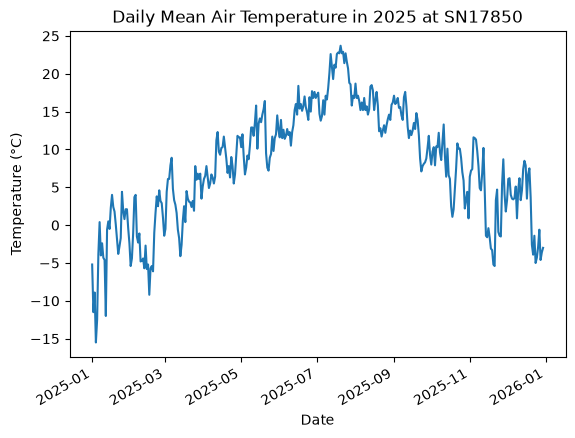

In [36]:
# Making the plot
fig, ax = plt.subplots()
ax.plot(df["date"], df["temperature"])

# Formatting the plot
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily Mean Air Temperature in 2025 at SN17850")

# Make the x-axis labels more readable
fig.autofmt_xdate()

# Show the plot
plt.show()

The plot shows that the temperatures varies quite a lot within the months, and it varies between the months as one would expect. The highest temperatures are found in July, and the lowest are found in January.

Calculates the summary statistics for 2025 in a summary table, including mean, median, min and max temperatures.

In [37]:
# Making a summary table 
summary_table = df[["temperature"]].agg(["mean", "median", "min", "max"]).round(2)
print("\nSummary Table:")
print(summary_table)


Summary Table:
        temperature
mean            7.9
median          8.4
min           -15.5
max            23.7


The summary table gives that the lowest temperature for 2025 was -15,5 and the highest was 23,7. The mean temperature was 7,9. 

## Task 2
To request data for precipitation as well, we reused the code from Task 1 and changed the `elements` parameter to `sum(precipitation_amountP1D)`. The result could then be stored in the variable `precipitation_data`:

In [38]:
# From the task description, reused from task 1
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# From the example code, reused from 1
# Issue an HTTP GET request for air temp
temperature_response = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
temperature_data = temperature_response.json()["data"]


# Changing the parameters to find precipitation instead
# Set timeoffsets to default so only PT6H data is used
# Frost recommended to not use PT18H (according to ChatGPT)
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2025-12-31',
"timeoffsets": "default"
}

# From the example code, modified for precipitation
# Issue an HTTP GET request for precipitation
precipitation_response = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
precipitation_data = precipitation_response.json()["data"]

Dates and values were then extracted and converted to datetime objects:

In [39]:
# Extract dates and values for temperature
temperature_dates = [
    item["referenceTime"] for item in temperature_data    # kan kanskje fjerne !!!
]
temperatures = [
    item["observations"][0]["value"] for item in temperature_data # kan kanskje fjerne!!!
]

# Extract dates and values for precipitation
precipitation_dates = [
    item["referenceTime"] for item in precipitation_data
]
precipitation = [
    item["observations"][0]["value"] for item in precipitation_data
]

# Convert dates to datetime objects
temperature_dates = pd.to_datetime(temperature_dates) # kan kanskje fjerne!!
precipitation_dates = pd.to_datetime(precipitation_dates)

The plot was then made in the same way as in task 1, now with data from both `temperature_dates` and `precipitation_dates`:

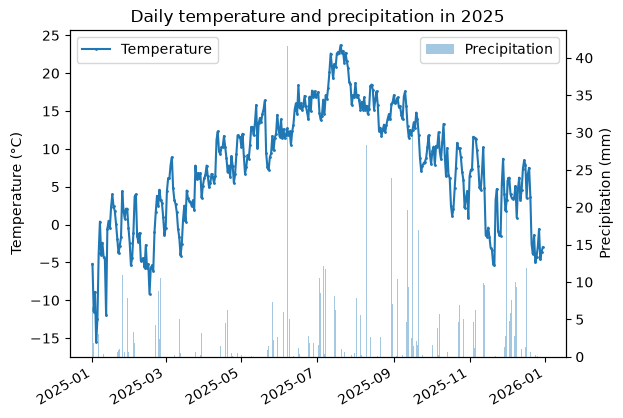

In [40]:
# Making the plot
fig, ax1 = plt.subplots()

# For temperature
ax1.plot(
    temperature_dates, temperatures,
    marker=".", markersize=2, label="Temperature"
)
ax1.set_ylabel("Temperature (°C)")

# For precipitation
ax2 = ax1.twinx()
ax2.bar(
    precipitation_dates, precipitation,
    width=0.5, alpha=0.4, label="Precipitation"
)
ax2.set_ylabel("Precipitation (mm)")

# Adding legend for readability
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

# Adding title
plt.title("Daily temperature and precipitation in 2025")
fig.autofmt_xdate() 
plt.show()

The figure shows a plot illustrating both  values. We chose to portray the precipitation amount as bars and the temperatures as a line, to make it easier to differentiate between the two. As expected, the plot shows that the daily temperatures were lower in the winter months, often dipping below zero. Temperature rose as summer approached, and reached a peak around August. Precipitation seems to have peaked in June, but overall there appears to have been more days with a higher mm of percipitation during the later months of the year.

## Task 4
To look for heatwaves, we first reused the code from Task 1 and switched the `element` parameter to `max(air_temperature P1D)`. The data could then be saved in the variable `temperature_data`.

In [41]:
# From the task description, reused from task 1
# Switched elements to max instead of mean
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'max(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# From the example code, reused from task 1 1
# Issue an HTTP GET request for air temp
temperature_response = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
temperature_data = temperature_response.json()["data"]

In order for the function to work regardless of the station name/id and year, we also fetched the station information and stored it in the variable `station_name`.

In [42]:
# Fetch station information
source_endpoint = 'https://frost.met.no/sources/v0.jsonld'

source_response = requests.get(
    source_endpoint,
    params={'ids': parameters['sources']},
    auth=(client_id, '')
)

source_data = source_response.json()
station_name = source_data["data"][0]["name"]

The necessary data was then extracted in the same way as before and converted to datetime objects.

In [43]:
# Extract dates and values for temperature
temperature_dates = [
    item["referenceTime"] for item in temperature_data
]
temperatures = [
    item["observations"][0]["value"] for item in temperature_data
]

# Convert dates to datetime objects
temperature_dates = pd.to_datetime(temperature_dates)

The function `count_heatwaves()` uses a for loop to iterate through the temperatures and dates. It then checks if the temperature surpassed 26 degrees. If it did, the code adds +1 to the `consecutive_days` variable. If the number there is 0, the code will also add the date to the `start_date` variable, meaning this is the beginning of a heatwave. With each iteration, it adds +1 if the temperature is high enough, and registers it as a heatwave if the number stored in `consecutive_days` reaches 5 or more days. The `end_date` is then added, and both dates are appended into the `heatwaves` list.

In [ ]:

def count_heatwaves():
    # Creating empty lists for the for loop
    consecutive_days = 0
    heatwaves = []
    start_date = None
    end_date = None
    
    for date, temperature in zip(temperature_dates, temperatures):
        if temperature >= 27:
            if consecutive_days == 0:
                start_date = date

            consecutive_days += 1
            end_date = date

        else:
            if consecutive_days >= 5:
                dates = f"{start_date.date()} - {end_date.date()}"
                heatwaves.append(dates)

            consecutive_days = 0
            
    # Checking again in case a heatwave continues after the last day of the data set       
    if consecutive_days >= 5:
        dates = f"{start_date.date()} - {end_date.date()}"
        heatwaves.append(dates)
    return heatwaves

heatwaves = count_heatwaves()

The result is then formatted in the correct format presented in the yml file. This is achieved through another function:

In [45]:
# Making a function to print using the yml format
def print_summary(heatwaves):
    print("dates:")
    for date in heatwaves:
        print(f"- {date}")

    print(f"station_id: {parameters['sources']}")
    print(f"station_name: {station_name}")
    print(f"year: {parameters['referencetime'][:4]}")
    
print_summary(heatwaves)

dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: ÅS
year: 2025


The output shows a summary of the data collected by the `count_heatwaves()` function. The dates listed show the consecutive period where the degrees surpassed 27. The station ID in this case symbolizes Ås, and the year the data has been collected from is 2025. As shown in the result, there was one heatwave that year, lasting from the 16th of July to the 20th.

## Task 5
The function `calculate_moving_avg()` calculates the 7-day moving average for temperature by using the `.mean()` function. `(window=7)` ensures this is done for 7 days at a time.

In [46]:
def calculate_moving_avg(temperatures):
    moving_avg = temperatures.rolling(window=7).mean() # calculates the mean of 7 days at a time
    return moving_avg

The function can be used on the 2025 mean temperature from Task 1 by using the dataframe created in Task 1. The plot is then plotted showing the moving average as a line and the daily temperature as points. 

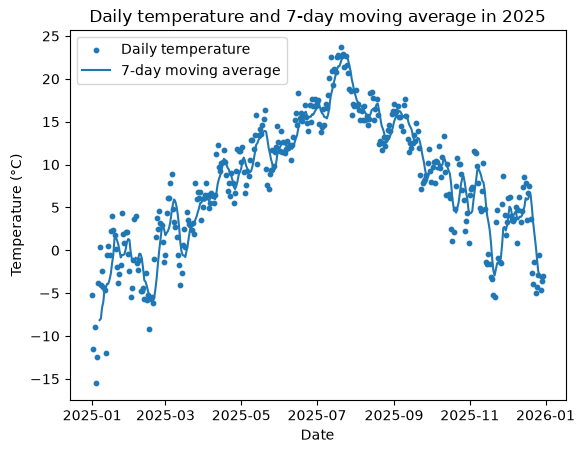

In [47]:
df["moving_avg"] = calculate_moving_avg(df["temperature"])

plt.scatter(df["date"], df["temperature"], label="Daily temperature", s=10)
plt.plot(df["date"], df["moving_avg"], label="7-day moving average")

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily temperature and 7-day moving average in 2025")
plt.legend()
plt.show()

The figure shows the average daily temperatures as points along the Y-axis, and the 7-day moving average as a line along the X-axis. The line seems to follow the daily temperature points as expected. The figure tells us that the highest temperature was around July/August, and this occured during a week where the 7-day moving average was also at its highest. As expected, temperatures were lower during the winter months and peaked in the middle of summer. At the beginning of the year in January and February, there are a few outliers from the 7-day moving average where the daily temperatures were much lower than the mean. 